In [1]:
import numpy as np
import tensorflow as tf

import tensorflow_datasets as tfds

In [2]:
# Load the MNIST dataset (handwritten digit images 0-9)
# with_info=True gives us metadata (like how many samples exist)
# as_supervised=True gives us data as (image, label) pairs instead of a dictionary
minst_dataset,minst_info= tfds.load(name='mnist', with_info=True, as_supervised=True)

In [4]:
# Split the dataset into training data and test data
mnist_train,mnist_test = minst_dataset['train'],minst_dataset['test']

# Decide how many samples to set aside for validation (10% of training data)
# Validation data is used during training to check performance on unseen data
num_validation_samples = 0.1 * minst_info.splits['train'].num_examples
num_validation_samples = tf.cast(num_validation_samples,tf.int64)

# Get the total number of test samples (used later for testing the final model)
num_test_samples = minst_info.splits['test'].num_examples
num_test_samples = tf.cast(num_test_samples,tf.int64)

In [5]:
# Function to normalize/scale pixel values
# Images have pixel values from 0-255; dividing by 255 makes them range from 0-1
# Neural networks train better with small, scaled numbers
def scale(image,label):
    image = tf.cast(image,tf.float32)
    image /= 255
    return image,label

# Apply the scaling function to both training and test data
scaled_train_and_validation_data = mnist_train.map(scale)
test_data = mnist_test.map(scale)

# Shuffle the data so it's not in a predictable order (important for good training)
# BUFFER_SIZE controls how many samples are loaded into memory at once for shuffling
BUFFER_SIZE = 10000
shuffled_train_and_validation_data = scaled_train_and_validation_data.shuffle(BUFFER_SIZE)

# Take the first chunk of shuffled data as the validation set
validation_data = shuffled_train_and_validation_data.take(num_validation_samples)

# Use the rest (everything except validation) as the actual training set
train_data = shuffled_train_and_validation_data.skip(num_validation_samples)

# Group data into batches instead of feeding one image at a time
# Batching speeds up training and stabilizes learning
BATCH_SIZE = 100 
train_data = train_data.batch(BATCH_SIZE)

# Validation data is used all at once (one big "batch") since it's just for checking, not training
validation_data = validation_data.batch(num_validation_samples)

# Same idea for test data — batch it all together
test_data = test_data.batch(num_test_samples)

# Extract validation inputs (images) and targets (labels) as actual tensors
# so they can be passed directly into model.fit()
validation_inputs, validation_targets = next(iter(validation_data))

In [16]:
# Define the shape of the network
input_size = 784      # 28x28 pixels flattened into a single line of 784 numbers
output_size = 10       # 10 possible digits (0 through 9)
hidden_layer_size = 100  # number of "neurons" in each hidden layer (arbitrary choice)

# Build the neural network model, layer by layer
model = tf.keras.Sequential([
    # Flatten turns the 28x28 image into a single long list of 784 numbers
    tf.keras.layers.Flatten(input_shape=(28, 28, 1)),

    # First hidden layer: 100 neurons, using ReLU activation (helps learn non-linear patterns)
    tf.keras.layers.Dense(hidden_layer_size, activation='relu'),

    # Second hidden layer: another 100 neurons with ReLU
    tf.keras.layers.Dense(hidden_layer_size, activation='relu'),

    # Output layer: 10 neurons (one per digit), softmax converts outputs into probabilities
    tf.keras.layers.Dense(output_size, activation='softmax')
])

In [13]:
# Configure the model for training:
# - optimizer='adam' → a smart algorithm that adjusts learning as it trains
# - loss='sparse_categorical_crossentropy' → measures how wrong predictions are (for integer labels)
# - metrics=['accuracy'] → track accuracy while training
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [15]:
# Number of times the model will go through the entire training dataset
NUM_EPOCHS = 5

# Train the model
# verbose=2 just controls how much info gets printed during training
model.fit(train_data,epochs= NUM_EPOCHS, validation_data = (validation_inputs,validation_targets),verbose=2)

Epoch 1/5
540/540 - 6s - 11ms/step - accuracy: 0.9050 - loss: 0.3289 - val_accuracy: 0.9498 - val_loss: 0.1674
Epoch 2/5
540/540 - 5s - 9ms/step - accuracy: 0.9587 - loss: 0.1370 - val_accuracy: 0.9693 - val_loss: 0.1024
Epoch 3/5
540/540 - 5s - 9ms/step - accuracy: 0.9708 - loss: 0.0946 - val_accuracy: 0.9732 - val_loss: 0.0883
Epoch 4/5
540/540 - 6s - 10ms/step - accuracy: 0.9774 - loss: 0.0735 - val_accuracy: 0.9783 - val_loss: 0.0697
Epoch 5/5
540/540 - 5s - 9ms/step - accuracy: 0.9818 - loss: 0.0566 - val_accuracy: 0.9822 - val_loss: 0.0584


In [14]:
# Test the trained model on completely unseen data (test set)
# This tells us how well it generalizes to new digits it has never seen
test_loss,test_accuracy = model.evaluate(test_data)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.1207 - loss: 2.3745


In [10]:
print('Test loss: {0:.2f}. Test accuracy: {1:.2f}%'.format(test_loss,test_accuracy*100.))

Test loss: 0.09. Test accuracy: 97.11%


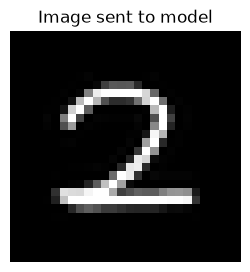

Prediction probabilities:
0: 0.00%
1: 3.44%
2: 96.39%
3: 0.09%
4: 0.00%
5: 0.00%
6: 0.00%
7: 0.08%
8: 0.00%
9: 0.00%


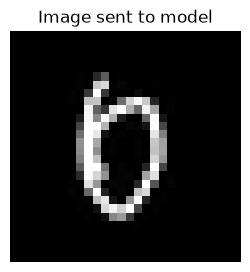

Prediction probabilities:
0: 72.32%
1: 0.03%
2: 0.60%
3: 0.00%
4: 9.66%
5: 1.67%
6: 0.61%
7: 13.29%
8: 0.02%
9: 1.78%


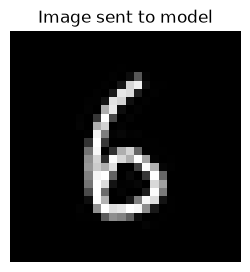

Prediction probabilities:
0: 0.70%
1: 0.03%
2: 0.47%
3: 0.00%
4: 0.14%
5: 0.64%
6: 96.23%
7: 0.00%
8: 1.79%
9: 0.00%


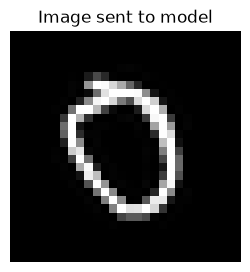

Prediction probabilities:
0: 79.25%
1: 0.00%
2: 0.24%
3: 0.04%
4: 0.04%
5: 0.24%
6: 0.26%
7: 2.26%
8: 0.14%
9: 17.54%


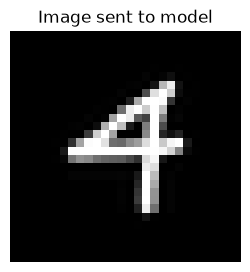

Prediction probabilities:
0: 0.00%
1: 0.00%
2: 0.00%
3: 0.00%
4: 99.92%
5: 0.00%
6: 0.00%
7: 0.06%
8: 0.00%
9: 0.02%


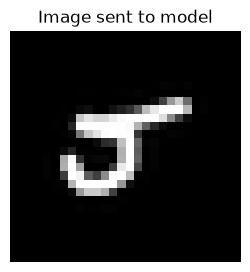

Prediction probabilities:
0: 1.56%
1: 8.26%
2: 1.87%
3: 0.01%
4: 2.62%
5: 71.46%
6: 0.15%
7: 7.88%
8: 5.89%
9: 0.29%


In [11]:
import tkinter as tk
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# SETTINGS
# ============================================================

CANVAS_SIZE = 280
BRUSH_SIZE = 18


# ============================================================
# CREATE WINDOW
# ============================================================

root = tk.Tk()
root.title("MNIST Digit Predictor")

canvas = tk.Canvas(
    root,
    width=CANVAS_SIZE,
    height=CANVAS_SIZE,
    bg="black",
    cursor="cross"
)

canvas.pack(padx=10, pady=10)


# ============================================================
# PIL IMAGE
# This stores the actual drawing
# ============================================================

image = Image.new(
    "L",
    (CANVAS_SIZE, CANVAS_SIZE),
    0
)

draw = ImageDraw.Draw(image)


# ============================================================
# MOUSE DRAWING
# ============================================================

last_x = None
last_y = None


def start_drawing(event):
    global last_x, last_y

    last_x = event.x
    last_y = event.y


def draw_digit(event):
    global last_x, last_y

    if last_x is not None and last_y is not None:

        # Draw on Tkinter canvas
        canvas.create_line(
            last_x,
            last_y,
            event.x,
            event.y,
            fill="white",
            width=BRUSH_SIZE,
            capstyle=tk.ROUND,
            smooth=True
        )

        # Draw on PIL image
        draw.line(
            [last_x, last_y, event.x, event.y],
            fill=255,
            width=BRUSH_SIZE
        )

        # Make stroke ends round
        radius = BRUSH_SIZE // 2

        draw.ellipse(
            [
                event.x - radius,
                event.y - radius,
                event.x + radius,
                event.y + radius
            ],
            fill=255
        )

    last_x = event.x
    last_y = event.y


def stop_drawing(event):
    global last_x, last_y

    last_x = None
    last_y = None


canvas.bind("<Button-1>", start_drawing)
canvas.bind("<B1-Motion>", draw_digit)
canvas.bind("<ButtonRelease-1>", stop_drawing)


# ============================================================
# PREPROCESS DRAWING
# ============================================================

def preprocess_image():

    # Convert image to NumPy array
    img_array = np.array(image)

    # Find all pixels belonging to the digit
    rows, cols = np.where(img_array > 20)

    # Nothing was drawn
    if len(rows) == 0:
        return None

    # Find bounding box
    min_row = rows.min()
    max_row = rows.max()
    min_col = cols.min()
    max_col = cols.max()

    # Crop around digit
    cropped = image.crop(
        (
            min_col,
            min_row,
            max_col + 1,
            max_row + 1
        )
    )

    # Add some padding around digit
    width, height = cropped.size

    padding = 20

    padded = Image.new(
        "L",
        (
            width + padding * 2,
            height + padding * 2
        ),
        0
    )

    padded.paste(
        cropped,
        (padding, padding)
    )

    # Resize while keeping proportions
    width, height = padded.size

    scale = 20 / max(width, height)

    new_width = max(1, int(width * scale))
    new_height = max(1, int(height * scale))

    resized = padded.resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS
    )

    # Create MNIST-style 28x28 image
    final_image = Image.new(
        "L",
        (28, 28),
        0
    )

    # Center digit
    x = (28 - new_width) // 2
    y = (28 - new_height) // 2

    final_image.paste(
        resized,
        (x, y)
    )

    return final_image


# ============================================================
# PREDICT
# ============================================================

def predict_digit():

    processed_image = preprocess_image()

    if processed_image is None:

        result_label.config(
            text="Please draw a digit first!"
        )

        return

    # Convert to NumPy
    img_array = np.array(
        processed_image
    ).astype("float32")

    # Normalize 0-255 → 0-1
    img_array = img_array / 255.0

    # Show exactly what the model sees
    plt.figure(figsize=(3, 3))

    plt.imshow(
        img_array,
        cmap="gray"
    )

    plt.title("Image sent to model")

    plt.axis("off")

    plt.show()

    # Add batch and channel dimensions
    img_array = img_array.reshape(
        1,
        28,
        28,
        1
    )

    # Use your existing trained model
    prediction = model.predict(
        img_array,
        verbose=0
    )

    # Find highest probability
    predicted_digit = int(
        np.argmax(prediction)
    )

    confidence = float(
        np.max(prediction)
    )

    # Display result
    result_label.config(
        text=(
            f"Prediction: {predicted_digit}\n"
            f"Confidence: {confidence * 100:.2f}%"
        )
    )

    # Also print probabilities
    print("Prediction probabilities:")

    for digit, probability in enumerate(
        prediction[0]
    ):
        print(
            f"{digit}: {probability * 100:.2f}%"
        )


# ============================================================
# CLEAR
# ============================================================

def clear_canvas():

    global image, draw

    # Clear Tkinter canvas
    canvas.delete("all")

    # Create new black image
    image = Image.new(
        "L",
        (CANVAS_SIZE, CANVAS_SIZE),
        0
    )

    draw = ImageDraw.Draw(image)

    # Reset result
    result_label.config(
        text="Prediction: -\nConfidence: -"
    )


# ============================================================
# BUTTONS
# ============================================================

button_frame = tk.Frame(root)

button_frame.pack(pady=5)


predict_button = tk.Button(
    button_frame,
    text="Predict",
    command=predict_digit,
    width=12
)

predict_button.pack(
    side=tk.LEFT,
    padx=5
)


clear_button = tk.Button(
    button_frame,
    text="Clear",
    command=clear_canvas,
    width=12
)

clear_button.pack(
    side=tk.LEFT,
    padx=5
)


# ============================================================
# RESULT LABEL
# ============================================================

result_label = tk.Label(
    root,
    text="Prediction: -\nConfidence: -",
    font=("Arial", 14)
)

result_label.pack(
    pady=10
)


# ============================================================
# START WINDOW
# ============================================================

root.mainloop()